# Day 1: Object Detection Concepts and YOLO Inference

Goal: understand the basic ideas behind object detection and run a pretrained YOLO model on sample images.



Setup

In [1]:
!pip -q install ultralytics

In [2]:
import torch
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
from IPython.display import display

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cpu
CUDA available: False


Object detection: what does the model predict?

Object detection identifies objects in an image and predicts a location for each object.

A detection usually contains:
- **Bounding box:** the rectangle around an object, commonly represented by `(x1, y1, x2, y2)` pixel coordinates.
- **Class label:** the predicted category, such as person, car or dog.
- **Confidence score:** the model's confidence in that detection.

Unlike image classification, object detection can identify multiple objects and their locations in one image.

Intersection over Union (IoU)

IoU measures how much a predicted box overlaps the ground-truth box.

\[
IoU = \frac{Area(\text{prediction} \cap \text{ground truth})}
{Area(\text{prediction} \cup \text{ground truth})}
\]

IoU ranges from 0 to 1. A value of 1 means the boxes overlap perfectly; 0 means they do not overlap.

In [3]:
def calculate_iou(box_a, box_b):
    # Boxes use (x1, y1, x2, y2) format.
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    inter_x1 = max(ax1, bx1)
    inter_y1 = max(ay1, by1)
    inter_x2 = min(ax2, bx2)
    inter_y2 = min(ay2, by2)

    inter_w = max(0, inter_x2 - inter_x1)
    inter_h = max(0, inter_y2 - inter_y1)
    intersection = inter_w * inter_h

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

box_1 = (10, 10, 50, 50)
box_2 = (20, 20, 60, 60)
print("IoU:", round(calculate_iou(box_1, box_2), 3))

IoU: 0.391


Precision, recall and mAP

- **Precision:** of all predicted detections, how many were correct?
- **Recall:** of all real objects, how many did the model find?
- **Average Precision (AP):** summarizes the precision-recall curve for one class.
- **mean Average Precision (mAP):** averages AP across classes. Object-detection benchmarks commonly report mAP at a specified IoU threshold (for example, mAP50) and averaged across IoU thresholds (for example, mAP50-95).

A detection is considered a true positive only when its predicted class and overlap meet the evaluation rules. The IoU threshold therefore affects precision, recall and AP.

Anchor-based vs anchor-free detectors

- **Anchor-based:** predicts adjustments and class scores relative to predefined reference boxes (anchors). Anchor sizes and aspect ratios are design choices.
- **Anchor-free:** predicts object locations without relying on a predefined set of anchor boxes, often by estimating object centres or box boundaries directly.

Both approaches are used in object detection. The exact design depends on the model architecture and version.

One-stage vs two-stage detectors

- **One-stage detectors (YOLO):** predict boxes and classes in a single detection pipeline. They are commonly chosen when speed is important.
- **Two-stage detectors (Faster R-CNN):** first generate region proposals, then classify and refine those regions. This separates proposal generation from final detection and can be computationally heavier.

This is a high-level distinction; modern detector designs have many variations.

Load a pretrained YOLO model

In [4]:
# YOLO11n is a small pretrained model. The weights download on first use.
model = YOLO("yolo11n.pt")
print("Model loaded.")

Model loaded.


Run detection on a sample image

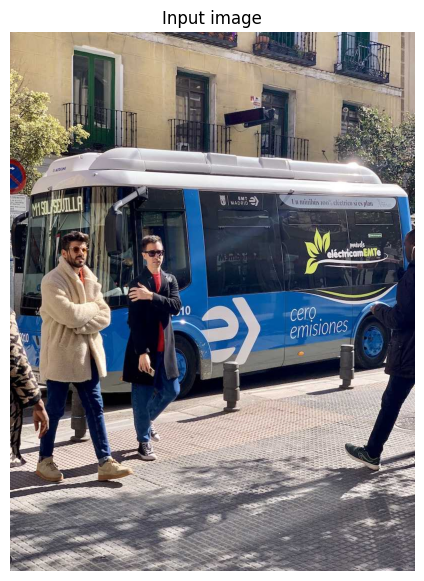

In [5]:
# Ultralytics provides this sample image URL for inference examples.
image_url = "https://ultralytics.com/images/bus.jpg"
sample_image = Image.open(__import__("requests").get(image_url, stream=True).raw).convert("RGB")

plt.figure(figsize=(10, 7))
plt.imshow(sample_image)
plt.axis("off")
plt.title("Input image")
plt.show()

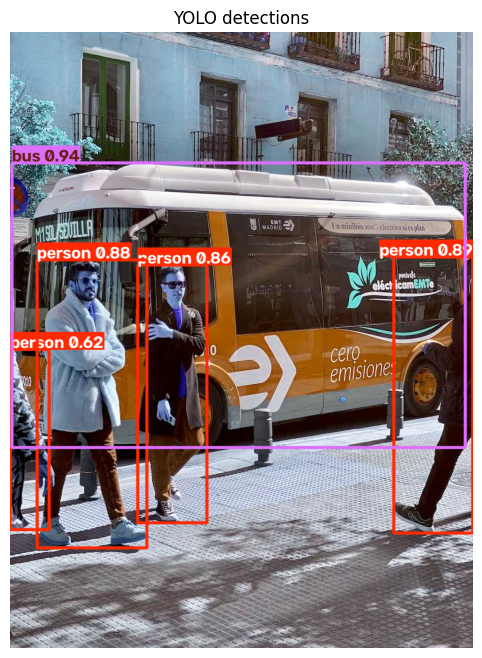

In [6]:
results = model.predict(source=sample_image, conf=0.25, verbose=False)
result = results[0]

# Display the image with predicted boxes, class names and confidence scores.
annotated_image = result.plot()
plt.figure(figsize=(12, 8))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("YOLO detections")
plt.show()

Inspect the detections

In [7]:
if result.boxes is None or len(result.boxes) == 0:
    print("No objects detected.")
else:
    rows = []
    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        rows.append({
            "class": model.names[class_id],
            "confidence": round(confidence, 3),
            "x1": round(x1, 1),
            "y1": round(y1, 1),
            "x2": round(x2, 1),
            "y2": round(y2, 1)
        })

    import pandas as pd
    detections_df = pd.DataFrame(rows)
    display(detections_df)

,class,confidence,x1,y1,x2,y2
0,bus,0.940,3.8,229.4,796.2,728.4
1,person,0.888,671.0,394.8,809.8,878.7
2,person,0.878,47.4,399.6,239.3,904.2
3,person,0.856,223.1,408.7,344.5,860.4
4,person,0.622,0.0,556.1,68.9,872.4


Try changing the confidence threshold

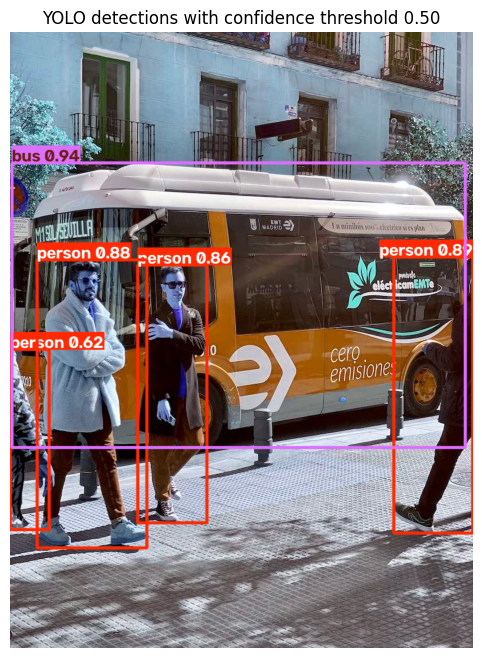

Detections at 0.25: 5
Detections at 0.50: 5


In [8]:
# Higher confidence thresholds usually show fewer detections.
results_high_conf = model.predict(source=sample_image, conf=0.50, verbose=False)
high_conf_image = results_high_conf[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(high_conf_image)
plt.axis("off")
plt.title("YOLO detections with confidence threshold 0.50")
plt.show()

print("Detections at 0.25:", len(result.boxes))
print("Detections at 0.50:", len(results_high_conf[0].boxes))